In [69]:
import numpy as np
import torch 
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons

torch.Size([1000, 2])


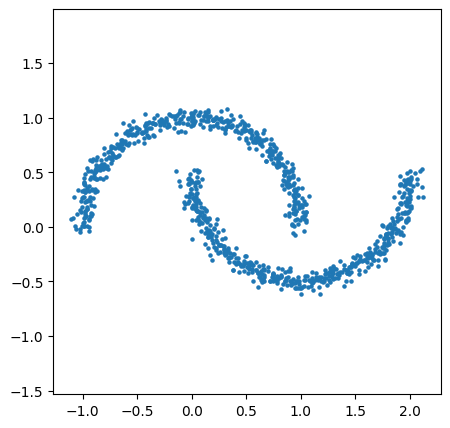

In [70]:
x, _ = make_moons(
    n_samples=1000,
    noise=0.05,
    random_state=42
)

x0 = torch.tensor(x, dtype=torch.float32)
print(x0.shape)

plt.figure(figsize=(5, 5))
plt.scatter(x0[:, 0], x0[:, 1], s=5)
plt.axis("equal")
plt.show()

In [71]:
x0 = (x0-x0.mean(dim=0))/x0.std(dim=0)

print(x0.mean(dim=0))
print(x0.std(dim=0))

tensor([-1.0252e-08,  1.1444e-08])
tensor([1., 1.])


# Diffusion

## 1. Forward Process

### Definition

- Forward distribution:

  $$
  q(x_t \mid x_{t-1}) = \mathcal{N}\left(\sqrt{1-\beta_t}x_{t-1}, \beta_t I\right)
  $$

- Equivalent sampling form:

  $$
  x_t = \sqrt{1-\beta_t}x_{t-1} + \sqrt{\beta_t}\epsilon
  $$

  where $\epsilon \sim \mathcal{N}(0,I)$.


### Why do we use square roots?

- Because variance scales with the **square of a coefficient**:

  $$
  \operatorname{Var}(aX) = a^2\operatorname{Var}(X)
  $$

- If $\operatorname{Var}(x_{t-1})=I$ and $\epsilon\sim\mathcal N(0,I)$:

  $$
  \begin{aligned}
  x_t &= \sqrt{1-\beta_t}x_{t-1} + \sqrt{\beta_t}\epsilon
  \\[4pt]
  \operatorname{Var}(x_t) &= \operatorname{Var}\left(\sqrt{1-\beta_t}x_{t-1} + \sqrt{\beta_t}\epsilon\right)
  \\
  &= (1-\beta_t)\operatorname{Var}(x_{t-1}) + \beta_t\operatorname{Var}(\epsilon)
  \\
  &= (1-\beta_t)I + \beta_t I
  \\
  &= I
  \end{aligned}
  $$

- **Key idea:**  
  the square root makes the variance contribution equal to $\beta_t$.


---

## 2. Directly Sample $x_t$ from $x_0$

- Calculating

  `x₀ → x₁ → x₂ → ... → xₜ`

  step by step is too slow.


### Define $\alpha_t$

- Let:

  $$
  \alpha_t = 1-\beta_t
  $$

- Then each forward step becomes:

  $$
  x_t = \sqrt{\alpha_t}x_{t-1} + \sqrt{1-\alpha_t}\epsilon_t
  $$


### Expand $x_1$ and $x_2$

- Start from $t=1$:

  $$
  \begin{aligned}
  x_1 &= \sqrt{\alpha_1}x_0 + \sqrt{1-\alpha_1}\epsilon_1
  \\[4pt]
  x_2 &= \sqrt{\alpha_2}x_1 + \sqrt{1-\alpha_2}\epsilon_2
  \\
  &= \sqrt{\alpha_2}\left(\sqrt{\alpha_1}x_0 + \sqrt{1-\alpha_1}\epsilon_1\right) + \sqrt{1-\alpha_2}\epsilon_2
  \\
  &= \sqrt{\alpha_1\alpha_2}x_0 + \sqrt{\alpha_2(1-\alpha_1)}\epsilon_1 + \sqrt{1-\alpha_2}\epsilon_2
  \end{aligned}
  $$


### Combine the Noise Terms

- Since $\epsilon_1,\epsilon_2\sim\mathcal N(0,I)$ are independent:

  $$
  \begin{aligned}
  \operatorname{Var}\left(\sqrt{\alpha_2(1-\alpha_1)}\epsilon_1 + \sqrt{1-\alpha_2}\epsilon_2\right)
  &= \alpha_2(1-\alpha_1) + (1-\alpha_2)
  \\
  &= 1-\alpha_1\alpha_2
  \end{aligned}
  $$

- Therefore:

  $$
  \sqrt{\alpha_2(1-\alpha_1)}\epsilon_1 + \sqrt{1-\alpha_2}\epsilon_2
  \overset{d}{=}
  \sqrt{1-\alpha_1\alpha_2}\epsilon_{\text{new}}
  $$

  where

  $$
  \epsilon_{\text{new}} \sim \mathcal N(0,I)
  $$

- So:

  $$
  x_2 = \sqrt{\alpha_1\alpha_2}x_0 + \sqrt{1-\alpha_1\alpha_2}\epsilon_{\text{new}}
  $$


---

## 3. General Form

### Define cumulative $\bar{\alpha}_t$

- Define:

  $$
  \bar{\alpha}_t = \prod_{s=1}^{t}\alpha_s
  $$

- So:

  $$
  \alpha_1\alpha_2\cdots\alpha_t = \bar{\alpha}_t
  $$


### ⭐ One-step Formula

- Therefore:

  $$
  \boxed{
  x_t = \sqrt{\bar{\alpha}_t}x_0 + \sqrt{1-\bar{\alpha}_t}\epsilon
  }
  $$

  where

  $$
  \epsilon \sim \mathcal N(0,I)
  $$


### Interpretation

- $\sqrt{\bar{\alpha}_t}x_0$ → remaining **signal**
- $\sqrt{1-\bar{\alpha}_t}\epsilon$ → added **noise**

- As $t$ increases:

  **signal ↓, noise ↑**

- So instead of:

  `x₀ → x₁ → x₂ → ... → xₜ`

  we can directly sample:

  `x₀ → xₜ`

# Diffusion schedule
- It decise how much noise we wanna add in a timestep.
- usually, we use beta to represent noise.
- we can use many different approach to add noise, but for simple we use liner here.

In [72]:
T = 1000 #total step

def schedule(T, low=1e-4, high=0.02, device="cpu"):

    betas = torch.linspace(low, high, T, device=device)

    alphas = 1.0 - betas
    alpha_bars = torch.cumprod(alphas, dim=0)

    sche = {
        "betas": betas,
        "alphas": alphas,
        "alpha_bars": alpha_bars,
        "sqrt_alpha_bars": torch.sqrt(alpha_bars),
        "sqrt_one_minus_alpha_bars": torch.sqrt(1.0 - alpha_bars),
    }
    return sche

sched = schedule(T)

print(sched["betas"].shape)
print(sched["alphas"][:5])
print(sched["alpha_bars"][:5])
print(sched["alpha_bars"][-1])

torch.Size([1000])
tensor([0.9999, 0.9999, 0.9999, 0.9998, 0.9998])
tensor([0.9999, 0.9998, 0.9996, 0.9995, 0.9993])
tensor(4.0358e-05)


In [73]:
"""
We compute x_t on the fly instead of storing all x_t values,
because we want to sample different noise each time.
"""

def q_sample(x0, t, noise, sched, device="cpu"):
    """
    x0: clean data, shape [B, 2]
    t: timestep, [B]
    noise: Gaussian noise, shape [B, 2]
    """
    sqrt_alpha_bar_t = sched["sqrt_alpha_bars"][t].unsqueeze(1)
    sqrt_one_minus_alpha_bar_t = sched["sqrt_one_minus_alpha_bars"][t].unsqueeze(1)

    xt = sqrt_alpha_bar_t * x0 + sqrt_one_minus_alpha_bar_t * noise

    return xt

In [74]:
def sample(x0, T, batch, sched, device="cpu"):
    x0_batch = x0[torch.randint(0, x0.shape[0], (batch,))].to(device)
    t = torch.randint(0, T, (batch,), device=device)
    noise = torch.randn_like(x0_batch, device=device)

    xt = q_sample(x0 = x0_batch, t = t, noise = noise, sched=sched, device=device)
    return xt, t, noise

B = 32
xt, _, _ = sample(x0, T, B, sched)
print(xt.shape)

torch.Size([32, 2])


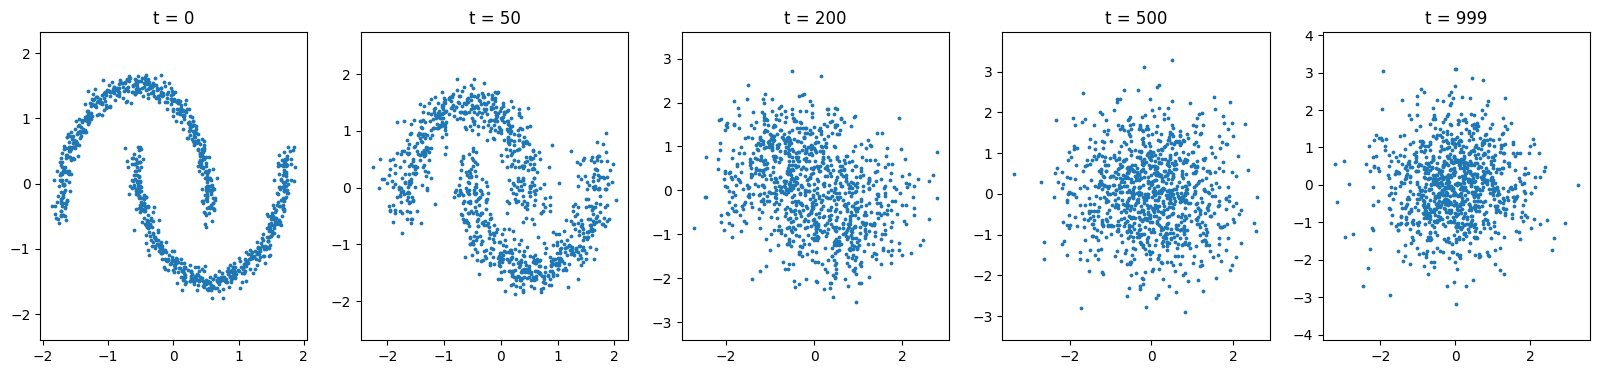

In [75]:
time_step = [0, 50, 200, 500, 999]

fig, axes = plt.subplots(1, 5, figsize=(20,4))

for ax, t in zip(axes, time_step):
    noise = torch.randn_like(x0)
    t_all = torch.full((x0.shape[0],), t, dtype=torch.long)
    xt = q_sample(x0, t_all, noise, sched)

    ax.scatter(
        xt[:,0],
        xt[:,1],
        s=3
    )
    ax.set_title(f"t = {t}")
    ax.axis("equal")
plt.show()

# Train a NN

In [76]:
class noisePredictor(nn.Module):
    def __init__(self,T):
        super().__init__()
        self.T = T
        self.fc1 = torch.nn.Linear(3,128)   # single sample dim (x1, x2, t)
        self.fc2 = nn.Linear(128,64)
        self.fc3 = nn.Linear(64,2)
    def forward(self,xt,t):
        t = t.to(xt.device)
        t = t.float()/self.T
        t = t.unsqueeze(1)
        x_input = torch.cat([xt, t], dim=1)
        x = F.relu(self.fc1(x_input))
        x = F.relu(self.fc2(x))
        x_output = self.fc3(x)
        return x_output

In [77]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = noisePredictor(T).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
x0 = x0.to(device)


def train(model, epochs, T, B, device):
    history = []
    sched = schedule(T, device=device)
    for epoch in range(epochs):
        xt, t, noise = sample(x0, T, B, sched, device=device)

        noise_pred = model(xt, t)

        loss = F.mse_loss(noise_pred, noise)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        history.append(loss.item())
        if (epoch+1)%1000 == 0:
            avg_loss = sum(history[-100:])/len(history[-100:])
            print(f'epoch = {epoch+1}, loss = {loss.item():.4f}, avg_loss = {avg_loss:.4f}')
    return history

epochs = 20000
B = 512
T = 1000
train(model, epochs, T, B, device)
print("model device =", next(model.parameters()).device)           



epoch = 1000, loss = 0.2341, avg_loss = 0.2411
epoch = 2000, loss = 0.2256, avg_loss = 0.2386
epoch = 3000, loss = 0.2686, avg_loss = 0.2359
epoch = 4000, loss = 0.2645, avg_loss = 0.2322
epoch = 5000, loss = 0.2611, avg_loss = 0.2347
epoch = 6000, loss = 0.2802, avg_loss = 0.2320
epoch = 7000, loss = 0.2248, avg_loss = 0.2263
epoch = 8000, loss = 0.2572, avg_loss = 0.2289
epoch = 9000, loss = 0.2384, avg_loss = 0.2286
epoch = 10000, loss = 0.1993, avg_loss = 0.2269
epoch = 11000, loss = 0.2562, avg_loss = 0.2271
epoch = 12000, loss = 0.2115, avg_loss = 0.2308
epoch = 13000, loss = 0.1838, avg_loss = 0.2228
epoch = 14000, loss = 0.2212, avg_loss = 0.2258
epoch = 15000, loss = 0.2021, avg_loss = 0.2293
epoch = 16000, loss = 0.2410, avg_loss = 0.2239
epoch = 17000, loss = 0.2266, avg_loss = 0.2270
epoch = 18000, loss = 0.1977, avg_loss = 0.2278
epoch = 19000, loss = 0.2887, avg_loss = 0.2309
epoch = 20000, loss = 0.2146, avg_loss = 0.2236
model device = cuda:0


# Reverse

## What do we want in the reverse process?

In the forward process, we gradually add noise:

$$
q(x_t \mid x_{t-1})
$$

For generation, we want to go in the opposite direction:

$$
q(x_{t-1} \mid x_t)
$$

If we knew this distribution, then we could start from pure noise

$$
x_T \sim \mathcal N(0, I)
$$

and repeatedly sample

$$
x_T \rightarrow x_{T-1} \rightarrow \cdots \rightarrow x_0
$$

to generate new data.

However, the true reverse distribution

$$
q(x_{t-1} \mid x_t)
$$

is hard to compute directly, because many possible clean data points could have produced the same noisy point $x_t$. In other words, from $x_t$ alone, we do not know which original $x_0$ it came from.

---

## Add one more condition: assume $x_0$ is known

During training, we actually do know the clean sample $x_0$, because we start from real data and add noise ourselves.

So instead of directly solving

$$
q(x_{t-1} \mid x_t),
$$

we first look at the easier posterior:

$$
q(x_{t-1} \mid x_t, x_0)
$$

This means:

> If I know the original clean point $x_0$, and I also know the noisy point $x_t$, what is the distribution of the previous noisy point $x_{t-1}$?

Using Bayes' rule, this posterior is proportional to:

$$
q(x_{t-1} \mid x_t, x_0)
\propto
q(x_t \mid x_{t-1})q(x_{t-1} \mid x_0)
$$

Both terms on the right are Gaussian distributions, so their product is also Gaussian. We do not need to prove the full algebra here; the important result is:

$$
q(x_{t-1} \mid x_t, x_0)
=
\mathcal N(\tilde\mu_t(x_t, x_0), \tilde\beta_t I)
$$

So the reverse step is also a Normal distribution. The only things we need are its mean and variance.

---

## But at generation time, $x_0$ is unknown

During sampling, we start from random noise. We do not have the true $x_0$.

So the neural network learns to predict the noise $\epsilon$ inside $x_t$:

$$
\epsilon_\theta(x_t, t)
$$

From the forward formula,

$$
x_t = \sqrt{\bar\alpha_t}x_0 + \sqrt{1-\bar\alpha_t}\epsilon
$$

if we can predict $\epsilon$, then we can estimate what direction removes noise from $x_t$.

This gives the DDPM reverse mean:

$$
\mu_\theta(x_t,t)
=
\frac{1}{\sqrt{\alpha_t}}
\left(
x_t -
\frac{\beta_t}{\sqrt{1-\bar\alpha_t}}
\epsilon_\theta(x_t,t)
\right)
$$

and the posterior variance:

$$
\tilde\beta_t
=
\frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}\beta_t
$$

So one reverse sampling step is:

$$
x_{t-1}
=
\mu_\theta(x_t,t)
+
\sqrt{\tilde\beta_t}z,
\quad
z \sim \mathcal N(0,I)
$$

When $t=0$, we do not add extra noise anymore.

---

## Intuition: mean and variance

### Mean

$$
\mu_\theta(x_t,t)
=
\frac{1}{\sqrt{\alpha_t}}
\left(
x_t -
\frac{\beta_t}{\sqrt{1-\bar\alpha_t}}
\epsilon_\theta(x_t,t)
\right)
$$

The mean is the model's best guess for where $x_{t-1}$ should be.

- $\epsilon_\theta(x_t,t)$ tells us the noise direction inside $x_t$.
- $\frac{\beta_t}{\sqrt{1-\bar\alpha_t}}$ controls how much of that predicted noise should be removed at this timestep.
- $\frac{1}{\sqrt{\alpha_t}}$ rescales the result back to the previous timestep, because the forward process slightly shrinks the signal by $\sqrt{\alpha_t}$.

So the mean means: **move $x_t$ a little bit away from noise and back toward data**.

### Variance

$$
\tilde\beta_t
=
\frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}\beta_t
$$

The variance controls how random the reverse step should be.

- Early in reverse sampling, when $t$ is large, the sample is still very noisy, so we allow more randomness.
- Near the end, when $t$ is small, the sample should become more precise, so the variance becomes smaller.
- The ratio $\frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}$ adjusts the noise level so it matches the amount of uncertainty between timestep $t$ and timestep $t-1$.

So the variance means: **do not deterministically jump to one point; sample a reasonable previous point according to how uncertain this timestep still is**.


In [78]:
@torch.no_grad
def inference(model, N, T, device):
    model.eval()

    x = torch.randn(N, 2, device=device)

    sched = schedule(T, device=device)

    for t in reversed(range(T)):
        t_batch = torch.full((N,), t, dtype=torch.long, device=device)

        noise_pred = model(x, t_batch)

        corrt_noise = (sched["betas"][t] * noise_pred)/sched["sqrt_one_minus_alpha_bars"][t]
        mean = 1/torch.sqrt(sched["alphas"][t]) * (x-corrt_noise)

        if t > 0:
            std = torch.sqrt(sched["betas"][t] * (1-sched["alpha_bars"][t-1]) / (1-sched["alpha_bars"][t]))

            z = torch.randn_like(x)
            x = mean + std * z
        else:
            x = mean

    return x

In [79]:
x = torch.randn(1000, 2, device=device)
N = 1000
T = 1000
samples = inference(model, N, T, device)

print(samples)

tensor([[-1.6917, -0.1677],
        [-0.1959, -1.1046],
        [ 1.5698, -0.3663],
        ...,
        [-0.6031, -0.3214],
        [-0.4809, -0.1360],
        [ 1.3735, -0.9460]], device='cuda:0')


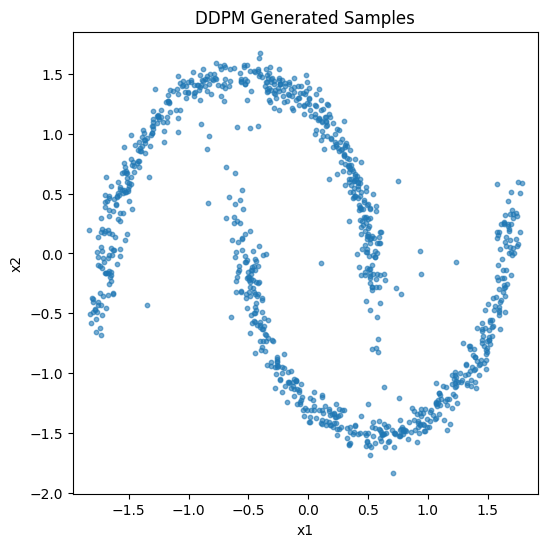

In [80]:
samples = samples.cpu().numpy()

plt.figure(figsize=(6, 6))
plt.scatter(
    samples[:, 0],
    samples[:, 1],
    s=10,
    alpha=0.6
)

plt.title("DDPM Generated Samples")
plt.xlabel("x1")
plt.ylabel("x2")
plt.axis("equal")
plt.show()